In [1]:
import os
import h5py
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
DATA_PATH='/home/bule/berner_daten_analyse/data'
OUTPUT_TENSOR_PATH=os.path.join(DATA_PATH, 'npz_output_tensors')
!ls $OUTPUT_TENSOR_PATH

413x128x128x28_dwi_bet_normalized_ants_lancosz.npz
413x128x128x28_dwi_bet_normalized_ndzoom.npz
413x128x128x28_dwi_bet_normalized_nilearn.npz
413x128x128x28_dwi_bet_normalized_trilinear.npz
413x128x128x28_dwi_skull_raw_trilinear.npz
413x240x240x155_dwi_bet_normalized_original.npz


# ants

In [3]:
prestring='413x128x128x28'
subselection='dwi_bet_normalized'
downsampling='ants_lancosz'


image_data_file=prestring+"_"+subselection+"_"+downsampling+".npz"
data = np.load(os.path.join(OUTPUT_TENSOR_PATH,image_data_file))
X_in =  np.array([data[key].tolist() for key in data.files])



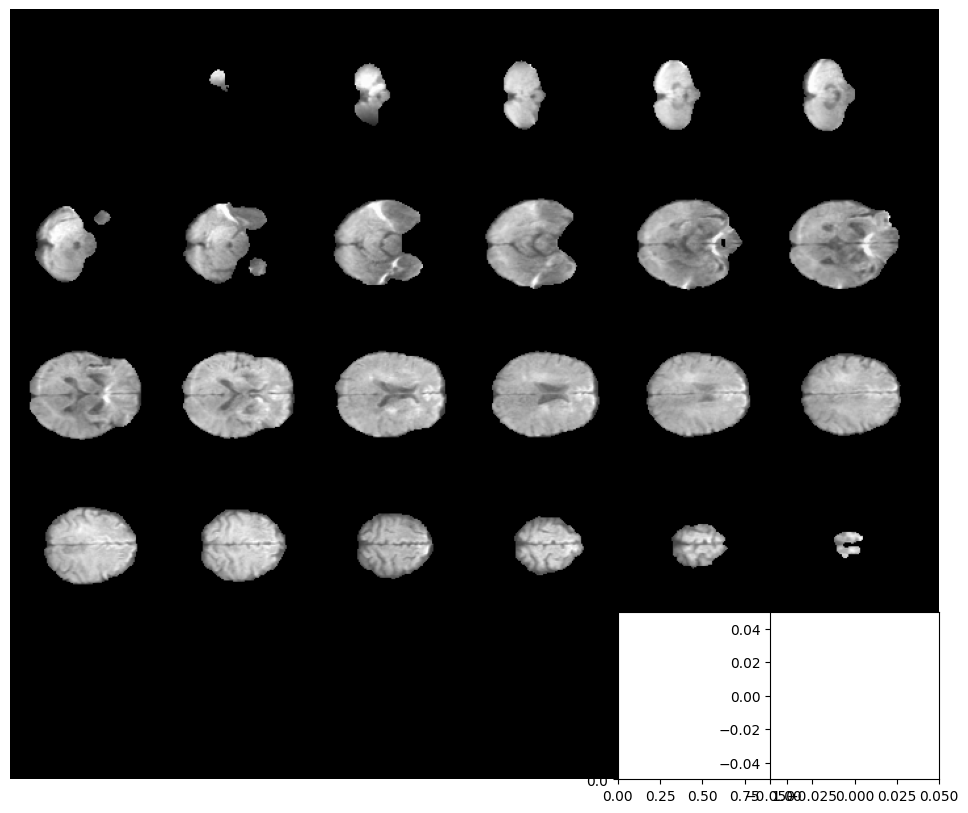

In [5]:
patient_zero_slices = X_in[11, :, :, :]
rows, cols = 5, 6
fig, axes = plt.subplots(rows, cols, figsize=(12, 10))

# Plot each slice
for i in range(rows * cols):
    if i < patient_zero_slices.shape[-1]:  # Ensure we don't exceed available slices
        ax = axes[i // cols, i % cols]
        ax.imshow(patient_zero_slices[:, :, i], cmap='gray')
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_frame_on(False)

plt.subplots_adjust(wspace=-0.1, hspace=-0.1)
plt.margins(0, 0)
plt.show()

## trilinear

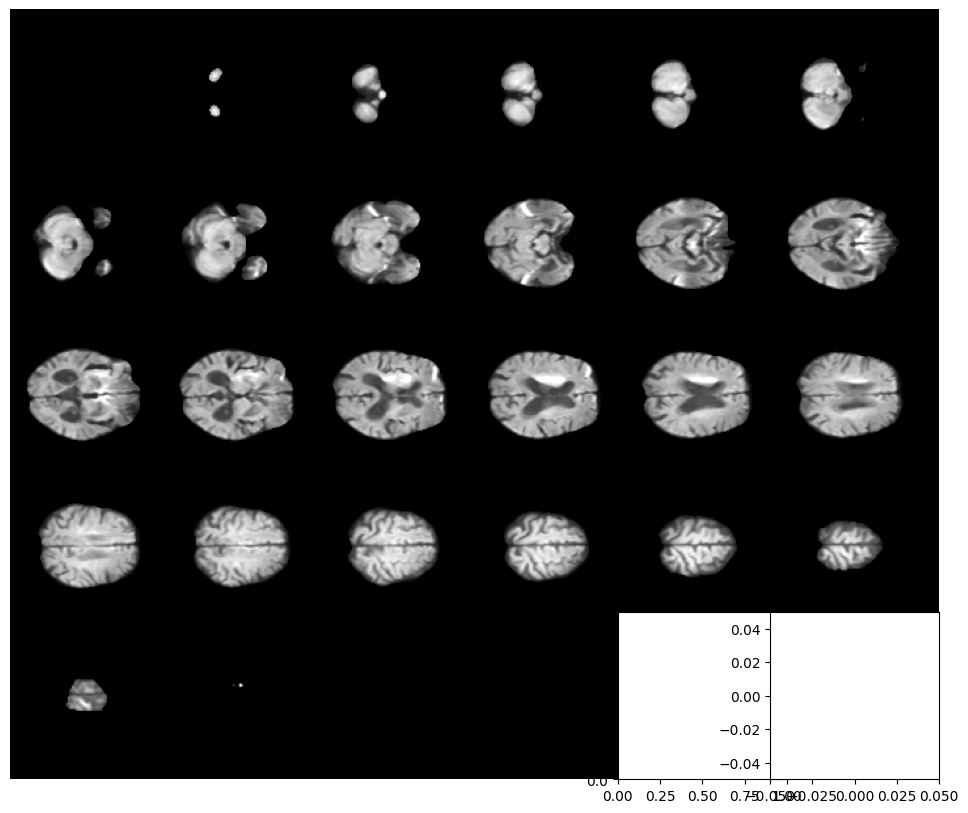

In [7]:
prestring='413x128x128x28'
subselection='dwi_bet_normalized'
downsampling='trilinear'


image_data_file=prestring+"_"+subselection+"_"+downsampling+".npz"
data = np.load(os.path.join(OUTPUT_TENSOR_PATH,image_data_file))
X_in =  np.array([data[key].tolist() for key in data.files])



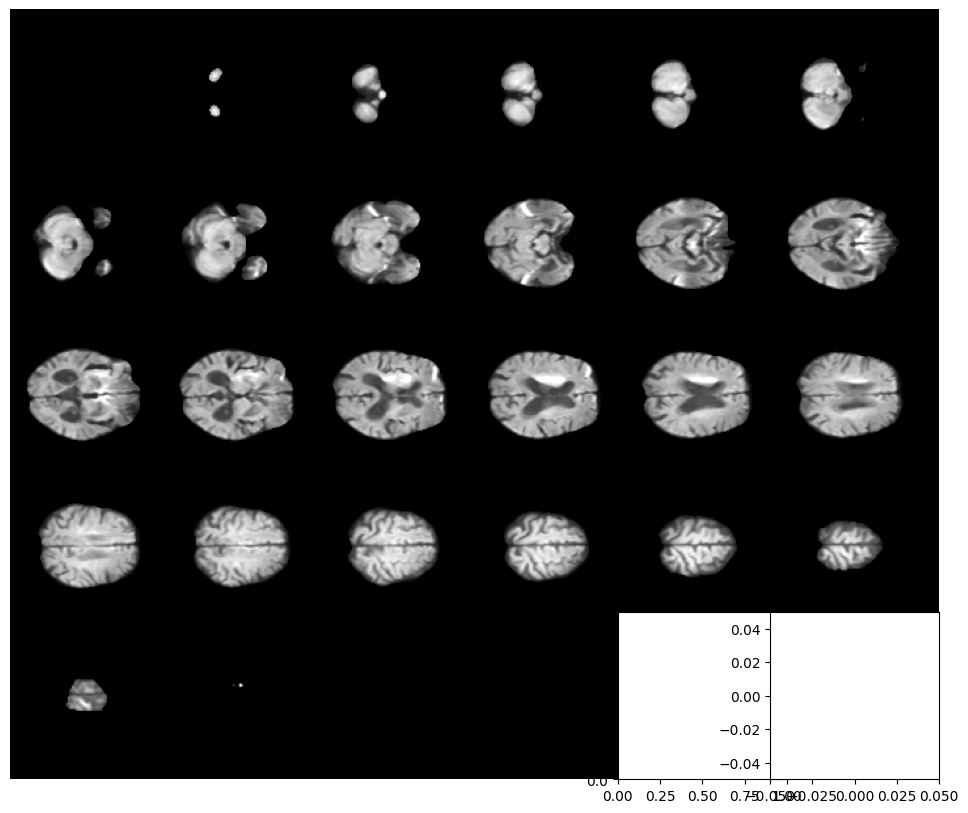

In [8]:
patient_zero_slices = X_in[10, :, :, :]
rows, cols = 5, 6
fig, axes = plt.subplots(rows, cols, figsize=(12, 10))

# Plot each slice
for i in range(rows * cols):
    if i < patient_zero_slices.shape[-1]:  # Ensure we don't exceed available slices
        ax = axes[i // cols, i % cols]
        ax.imshow(patient_zero_slices[:, :, i], cmap='gray')
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_frame_on(False)

plt.subplots_adjust(wspace=-0.1, hspace=-0.1)
plt.margins(0, 0)
plt.show()

## NiLearn

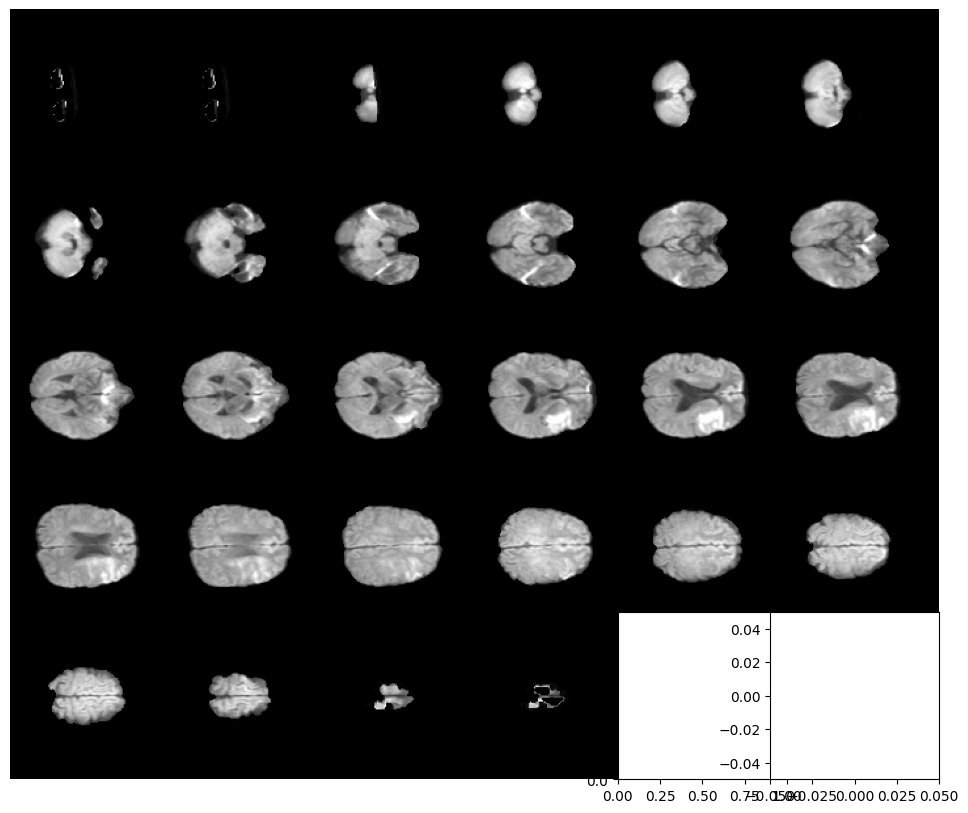

In [ ]:
prestring='413x128x128x28'
subselection='dwi_bet_normalized'
downsampling='nilearn'


image_data_file=prestring+"_"+subselection+"_"+downsampling+".npz"
data = np.load(os.path.join(OUTPUT_TENSOR_PATH,image_data_file))
X_in =  np.array([data[key].tolist() for key in data.files])



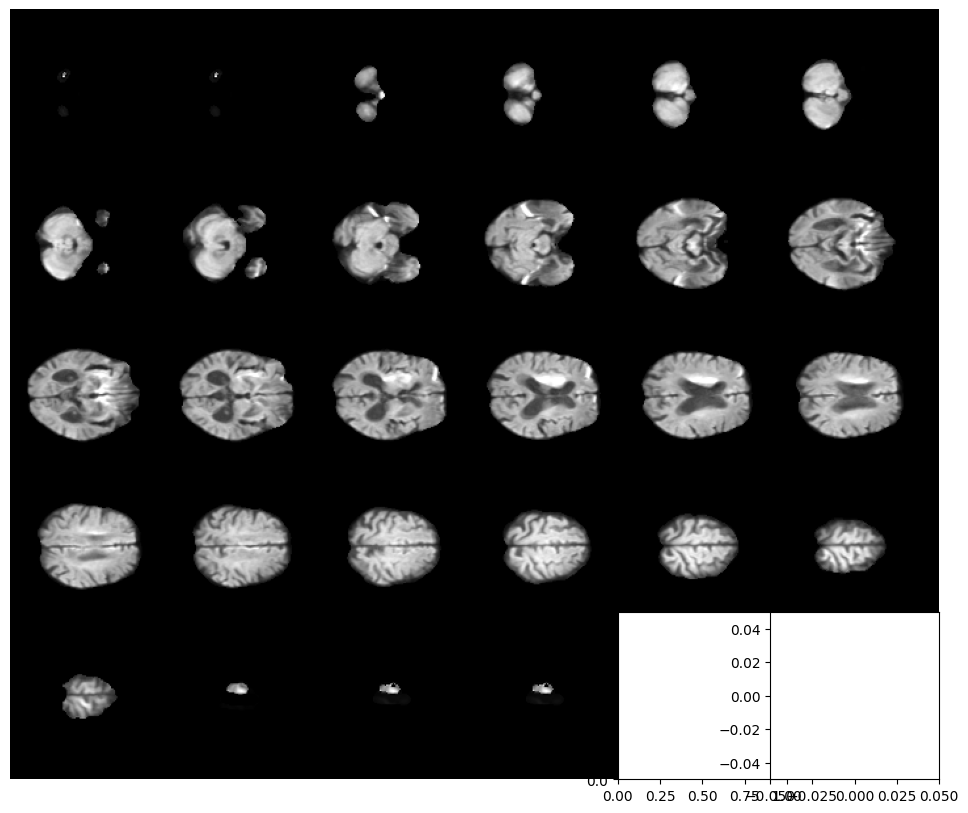

In [6]:
patient_zero_slices = X_in[10, :, :, :]
rows, cols = 5, 6
fig, axes = plt.subplots(rows, cols, figsize=(12, 10))

# Plot each slice
for i in range(rows * cols):
    if i < patient_zero_slices.shape[-1]:  # Ensure we don't exceed available slices
        ax = axes[i // cols, i % cols]
        ax.imshow(patient_zero_slices[:, :, i], cmap='gray')
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_frame_on(False)

plt.subplots_adjust(wspace=-0.1, hspace=-0.1)
plt.margins(0, 0)
plt.show()

# NDzoom

In [9]:
prestring='413x128x128x28'
subselection='dwi_bet_normalized'
downsampling='ndzoom'


image_data_file=prestring+"_"+subselection+"_"+downsampling+".npz"
data = np.load(os.path.join(OUTPUT_TENSOR_PATH,image_data_file))
X_in =  np.array([data[key].tolist() for key in data.files])



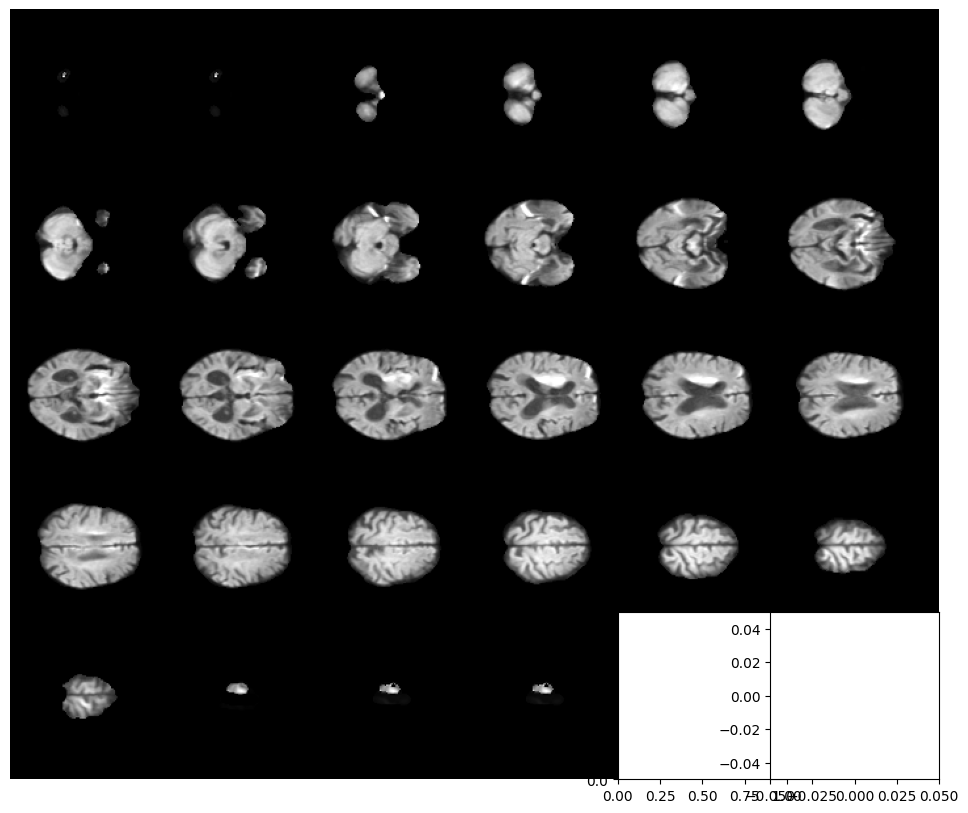

In [7]:
patient_zero_slices = X_in[10, :, :, :]
rows, cols = 5, 6
fig, axes = plt.subplots(rows, cols, figsize=(12, 10))

# Plot each slice
for i in range(rows * cols):
    if i < patient_zero_slices.shape[-1]:  # Ensure we don't exceed available slices
        ax = axes[i // cols, i % cols]
        ax.imshow(patient_zero_slices[:, :, i], cmap='gray')
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_frame_on(False)

plt.subplots_adjust(wspace=-0.1, hspace=-0.1)
plt.margins(0, 0)
plt.show()

# OLD data from DL vs Neurologist

"Deep learning versus neurologists: functional outcome prediction in LVO stroke patients undergoing mechanical thrombectomy"




read in 

In [ ]:
with h5py.File(DATA_PATH + "/data_bern_25_11_2020_preprocessed.h5", "r") as h5:
    X0 = h5["X_dwi"][:]
print(X0.shape, X0.min(), X0.max(), X0.mean(), X0.std())

In [ ]:
old_df=pd.read_csv(DATA_PATH + "/data_bern_25_11_2020_wide_all_nihss.csv")
old_df


Same resizing method as HEZO

In [ ]:
# Reshape the data to the correct dimension
dim = (128, 128, 28, 1)
from scipy import ndimage

X = np.empty((len(X0), 128, 128, 28, 3))
for i in range(len(X0)):
    scaling_factor = [dim[0]/X0[i].shape[0], dim[1]/X0[i].shape[1], dim[2]/X0[i].shape[2], dim[3]/X0[i].shape[3]]
    X[i,:,:,:,:] = ndimage.zoom(X0[i], scaling_factor, order = 1)
X[:,:,:,:,1] = X[:,:,:,:,0]
X[:,:,:,:,2] = X[:,:,:,:,0]

In [ ]:
resized_patient_images = {}
for i, pid in enumerate(old_df['p_id']):
    print(f"Processing patient {pid} ({i+1}/{len(old_df['p_id'])})...")
    resized_patient_images[str(pid)]= X[i]
np.savez_compressed(os.path.join(DATA_PATH,'berner_daten_25_11_2020_dwi_skull_raw_lisa_resized_28.npz'), **resized_patient_images)

In [ ]:
# Extract slices for patient zero
patient_zero_slices = X0[221, :, :, :].squeeze()

# Define grid size
rows, cols = 5, 6
fig, axes = plt.subplots(rows, cols, figsize=(12, 10))

# Plot each slice
for i in range(rows * cols):
    if i < patient_zero_slices.shape[-1]:  # Ensure we don't exceed available slices
        ax = axes[i // cols, i % cols]
        ax.imshow(patient_zero_slices[:, :, i], cmap='gray')
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_frame_on(False)

# Adjust layout to minimize spacing
plt.subplots_adjust(wspace=-0.1, hspace=-0.1)
plt.margins(0, 0)

plt.show()

In [ ]:
332/(332+75)

In [ ]:
from sklearn.model_selection import StratifiedKFold


df = old_df_full
# if "mrs" not in df.columns:
#     raise ValueError("Column 'mrs' not found in the dataset")

df["unfavorable"] = (df["mrs_3months"] >= 3).astype(int)
skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
df[[f'fold{i}' for i in range(10)]] = ""

# Assign folds
for fold, (train_idx, test_idx) in enumerate(skf.split(df, df["mrs_3months"])):
    train_set, test_set = df.iloc[train_idx], df.iloc[test_idx]
    
    skf_val = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
    val_size = int(0.1 * len(train_set))
    val_idx = np.random.choice(train_set.index, size=val_size, replace=False)
    val_set = train_set.loc[val_idx]
    
    df.loc[df.index.isin(test_set.index), f'fold{fold}'] = "test"
    df.loc[df.index.isin(val_set.index), f'fold{fold}'] = "val"
    df.loc[(df[f'fold{fold}'] == ""), f'fold{fold}'] = "train"

output_columns = [ "p_id", "mrs_3months", "unfavorable"] + [f'fold{i}' for i in range(10)]

df = df[output_columns]
df['p_idx']=df.index
# df.to_csv(os.path.join(DATA_DIR, 'data_bern_25_10_2020_10Fold_ids_test.csv'), index=False)
df

In [ ]:
filter_=df[df['fold0']=='train']
filter_['unfavorable'].value_counts()

In [ ]:
97/180

In [ ]:
filter_=df[df['fold1']=='val']
filter_['unfavorable'].value_counts()
13/19